## Task 3

### Task 3.1 - 1D heat equation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
L= 1.0
alpha = 0.1
T = 1.0

# The Analytical solution from the assignment
def analytical_solution(x, t):
    return np.sin(np.pi * x / L) * np.exp(-alpha * (np.pi / L)**2 * t)

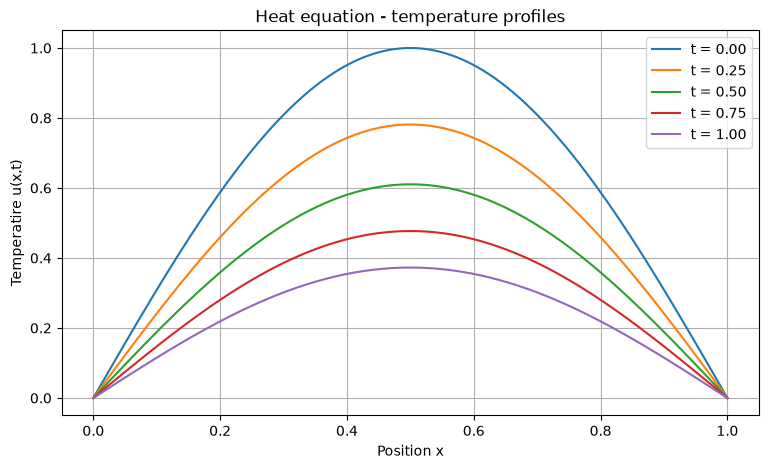

In [2]:
# Spatial grid
x = np.linspace(0, L, 200)

# Five chosen time points for visualising
times = np.linspace(0, T, 5)

# Plotting
plt.figure(figsize=(9, 5))

for t in times:
    u = analytical_solution(x, t)
    plt.plot(x, u, label=f"t = {t:.2f}")

plt.xlabel("Position x")
plt.ylabel("Temperatire u(x,t)")
plt.title("Heat equation - temperature profiles")
plt.legend()
plt.grid()
plt.show()

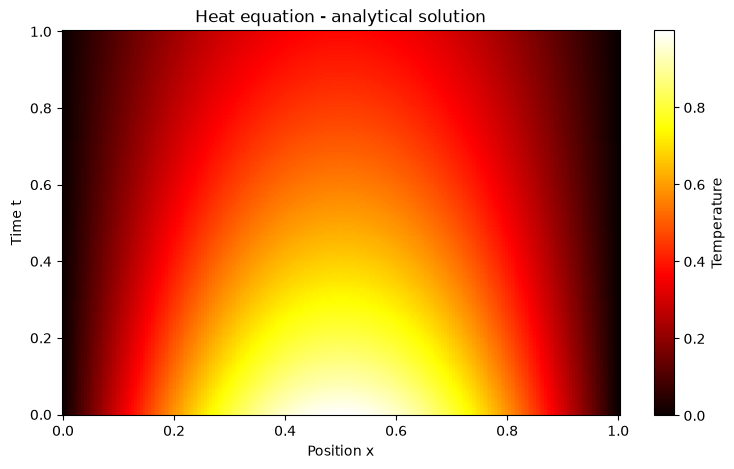

In [3]:
# Grid for space and time
x = np.linspace(0, L, 200)
t = np.linspace(0, T, 200)

X, TT = np.meshgrid(x, t)

# Evaluating analytical solution
U = analytical_solution(X, TT)

# Heatmap
plt.figure(figsize=(9, 5))

plt.pcolormesh(X, TT, U, shading="auto", cmap="hot")
plt.colorbar(label="Temperature")
plt.xlabel("Position x")
plt.ylabel("Time t")
plt.title("Heat equation - analytical solution")
plt.show()

### 3.2 - 1D heat equation

### 3.3 - 1D heat equation

#### Sampling

In [4]:
import torch

# Physics points

# Parameters
L = 1.0
T = 1.0
alpha = 0.1

# Number of points
N_x = 40
N_t = 40

# Create evenly spaced points for positions, x and time, t
x = torch.linspace(0, L, N_x)
t = torch.linspace(0, T, N_t)

# Create 2D grid. Combining the positions and time points
X, TT = torch.meshgrid(x, t, indexing='ij')

# Flatten and combine our 2D grid into a list of coordinate pairs of position and time
X_r = torch.stack((X.flatten(), TT.flatten()), dim=1)

print(X_r.shape)

torch.Size([1600, 2])


In [5]:
# Initial condition points
# Here we only need to variate the position, since the time is always zero

# Parameters
N_IC = 100

# Create evenly spaced points
x_IC = torch.linspace(0, L, N_IC)
t_IC = torch.zeros(N_IC)

# Combining position and time into coordinate pairs
X_IC = torch.stack((x_IC, t_IC), dim=1)

print(X_IC.shape)

torch.Size([100, 2])


In [6]:
# Boundary condition points
# Here we are variating the time, while we maintain the position at respectively 0 and L

# Parameters
N_BC = 100

# Create evenly spaced points
t_BC = torch.linspace(0, T, N_BC)

# Left boundary
x_left = torch.zeros(N_BC)

# Right boundary
x_right = torch.full((N_BC,), L)

# Create coordinate pairs
X_BC_left = torch.stack((x_left, t_BC), dim=1)
X_BC_right = torch.stack((x_right, t_BC), dim=1)

# Combine both boundaries
X_BC = torch.cat((X_BC_left, X_BC_right), dim=0)

print(X_BC.shape)

torch.Size([200, 2])


#### Construction of the Neural Network

##### Lidt noter: Vi bruger tanh,, da den er differentiabel, hvilket er skal bruges når vi snakker PINNS, da vi skal kunne beregne den afledte af outputtet med hensyn til inputtene

In [7]:
import torch
import torch.nn as nn

class PINN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32), # Første lag modtager to inputvariable, x og t, og producere 32 outputværdier
            nn.Tanh(), # Activation function. Makes the network capable of handling non-linear relationships

            nn.Linear(32, 32), # Second layer 32 input and 32 output
            nn.Tanh(),

            nn.Linear(32, 1) # 32 input and one final output - the temperature prediction for the given x and t.
        )

    def forward(self, inputs):
        return self.network(inputs)

In [8]:
# Initialise and testing the network

model = PINN()

# Test with one coordinate pair
test_input = torch.tensor([[0.5, 0.2]]) # Giving the network the position x = 0.5 and time t = 0.2

prediction = model(test_input)

print(prediction)

tensor([[0.1651]], grad_fn=<AddmmBackward0>)


##### Since we are training a PINN, we cant just compare the networks predictions with known labels. Our PINN has to comply with:
##### $\frac{\partial u}{\partial t} - \alpha \frac{\partial^2 u}{\partial x^2} = 0$  i.e our residual, how much our function deviates from the physics equation
##### And therefore we need to be able to calculate:
##### $\frac{\partial u_\theta}{\partial t}$ and $\frac{\partial^2 u_\theta}{\partial x^2}$
##### We can do this with PyTorchs torch.autograd.grad - Here we are differentiating the networks output with respect to its input variables. We use this to calculate the residual, and consequently, the physics loss.

In [ ]:
# Make a copy of the collocation points that allows differentiation
X_r_grad = X_r.clone().requires_grad_(True) # We have the 1,600 points in X_r. We want to calculate derivatives with respect to these inputs. We do this using requires_grad=True.

# Forward pass through the neural network
u = model(X_r_grad)

# First derivatives: du/dx and du/dt
grads = torch.autograd.grad(
    outputs=u, # What we want to differentiate
    inputs=X_r_grad, # What we want to differentiate with respect to
    grad_outputs=torch.ones_like(u), # Calculating the gradient of the sum of the outputs
    create_graph=True)[0] # Saving the calculation as part of new calculation diagram so that we can differentiate once more.

# The result becomes a matrix of dimensions (1600, 2) since we get one derivative with respect to each inputvariable

# We can therefore gather the derivatives like this:
u_x = grads[:, 0:1]
u_t = grads[:, 1:2]

# Second derivative: d2u/dx2 in the same way as before.
grads_x = torch.autograd.grad(
    outputs=u_x,
    inputs=X_r_grad,
    grad_outputs=torch.ones_like(u_x),
    create_graph=True)[0]


u_xx = grads_x[:, 0:1]

# PDE residual
residual = u_t - alpha * u_xx

# Check dimensions
print("u:", u.shape)
print("u_x:", u_x.shape)
print("u_t:", u_t.shape)
print("u_xx:", u_xx.shape)
print("Residual:", residual.shape)


u: torch.Size([1600, 1])
u_x: torch.Size([1600, 1])
u_t: torch.Size([1600, 1])
u_xx: torch.Size([1600, 1])
Residual: torch.Size([1600, 1])


##### Now we want to construct our loss-functions. From task 3.2 we have defined the three requirements, that our PINN must learn to comply with:
##### 1. The heat equation, physics loss. Measuring how much the residual deviates from zero
##### 2. The initial condition loss. It needs to know the temperaturedistribution at the starting time, meaning that we at time t=0 know the temperature along the whole rod. Our network therefore has to be able to recreate this temperaturedistribution. Therefore we compare with the known Initial condition from 3.2
##### 3. Boundary condition loss. We have to boundary conditions; that the temperature in each end of the rod always has to be zero. We already have X_BC_left and X_BC_right, that we can put through the network.

In [10]:
# 1.
loss_phys = torch.mean(residual**2) # Just using residual, since we already defined the residual in the last block

# 2.
u_IC = model(X_IC)
u_IC_exact = torch.sin(torch.pi * X_IC[:, 0:1] / L)
loss_IC = torch.mean((u_IC - u_IC_exact)**2)

# 3.
u_BC_left = model(X_BC_left)
u_BC_right = model(X_BC_right)
loss_BC = torch.mean(u_BC_left**2 + u_BC_right**2)

In [11]:
lambda_phys = 100.0
lambda_IC = 25.0
lambda_BC = 40.0

In [ ]:
# Calculating the total loss
loss_total = (
    lambda_phys * loss_phys
    + lambda_IC * loss_IC
    + lambda_BC * loss_BC)

## Training the network with ADAM optimizer

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001)

epochs = 5000

##### Gathering everything into our training loop


In [ ]:

# Store losses during training
# Adam loss histories
adam_loss_history = []

adam_loss_phys_history = []
adam_loss_IC_history = []
adam_loss_BC_history = []

for epoch in range(epochs):

    # 1. Calculate physics loss
    X_r_grad = X_r.clone().detach().requires_grad_(True)

    u = model(X_r_grad)

    grads = torch.autograd.grad(
        outputs=u,
        inputs=X_r_grad,
        grad_outputs=torch.ones_like(u),
        create_graph=True)[0]

    u_x = grads[:, 0:1]
    u_t = grads[:, 1:2]

    grads_x = torch.autograd.grad(
        outputs=u_x,
        inputs=X_r_grad,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True)[0]

    u_xx = grads_x[:, 0:1]

    residual = u_t - alpha * u_xx

    loss_phys = torch.mean(residual**2)

    # 2. Calculate initial condition loss
    u_IC = model(X_IC)
    u_IC_exact = torch.sin(torch.pi * X_IC[:, 0:1] / L)

    loss_IC = torch.mean((u_IC - u_IC_exact)**2)

    # 3. Calculate boundary condition loss
    u_BC_left = model(X_BC_left)
    u_BC_right = model(X_BC_right)

    loss_BC = torch.mean(u_BC_left**2 + u_BC_right**2)

    # 4. Calculate total loss
    loss_total = (
        lambda_phys * loss_phys
        + lambda_IC * loss_IC
        + lambda_BC * loss_BC)

    # 5. Update network parameters
    optimizer.zero_grad()
    loss_total.backward()
    optimizer.step()

    # Store loss for later visualization
    adam_loss_history.append(loss_total.item())

    adam_loss_phys_history.append(loss_phys.item())
    adam_loss_IC_history.append(loss_IC.item())
    adam_loss_BC_history.append(loss_BC.item())

    if (epoch + 1) % 500 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Total Loss: {loss_total.item():.8f}, "
            f"Physics: {loss_phys.item():.8f}, "
            f"IC: {loss_IC.item():.8f}, "
            f"BC: {loss_BC.item():.8f}")


Epoch 500/5000, Total Loss: 0.09003927, Physics: 0.00047928, IC: 0.00057035, BC: 0.00069633
Epoch 1000/5000, Total Loss: 0.01553778, Physics: 0.00012562, IC: 0.00005651, BC: 0.00003908
Epoch 1500/5000, Total Loss: 0.00848305, Physics: 0.00007561, IC: 0.00001808, BC: 0.00001175
Epoch 2000/5000, Total Loss: 0.00456278, Physics: 0.00004209, IC: 0.00000662, BC: 0.00000470
Epoch 2500/5000, Total Loss: 0.00249402, Physics: 0.00002368, IC: 0.00000242, BC: 0.00000163
Epoch 3000/5000, Total Loss: 0.00156383, Physics: 0.00001505, IC: 0.00000110, BC: 0.00000079
Epoch 3500/5000, Total Loss: 0.00146410, Physics: 0.00001155, IC: 0.00000377, BC: 0.00000537
Epoch 4000/5000, Total Loss: 0.00097007, Physics: 0.00000934, IC: 0.00000060, BC: 0.00000052
Epoch 4500/5000, Total Loss: 0.01649433, Physics: 0.00002447, IC: 0.00012329, BC: 0.00027412
Epoch 5000/5000, Total Loss: 0.02312393, Physics: 0.00003423, IC: 0.00016642, BC: 0.00038851


##### Comparing to the analytical solution and visualising

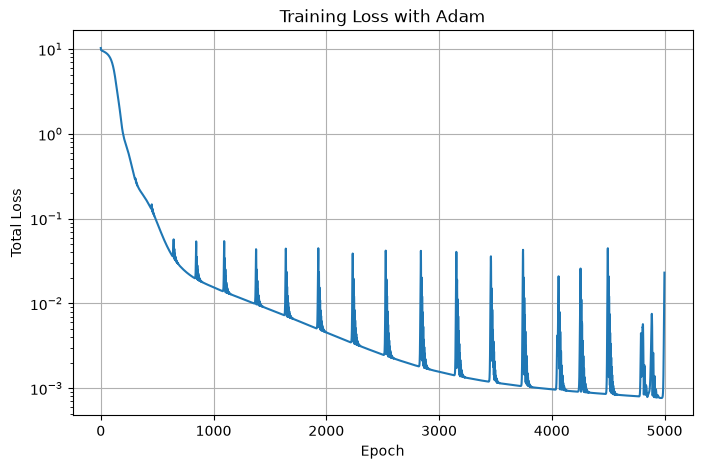

In [15]:
import matplotlib.pyplot as plt

# Plotting the training loss

plt.figure(figsize=(8, 5))

plt.semilogy(adam_loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total Loss")
plt.title("Training Loss with Adam")
plt.grid(True)

plt.show()

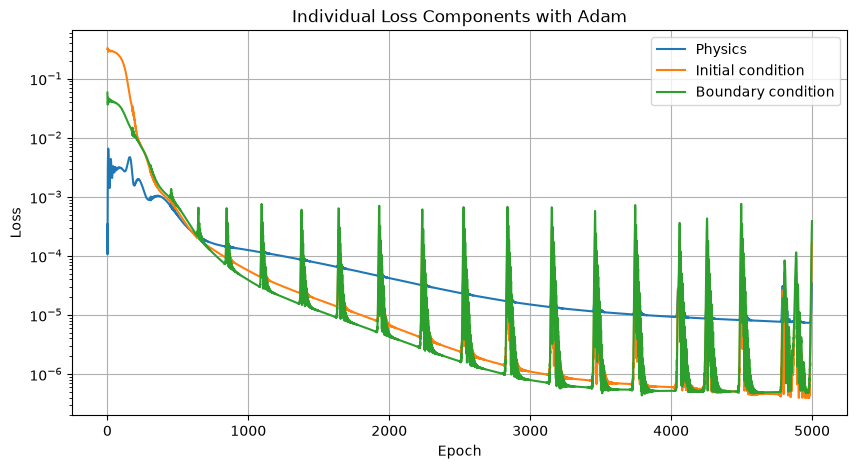

In [16]:
plt.figure(figsize=(10, 5))

plt.semilogy(adam_loss_phys_history, label="Physics")
plt.semilogy(adam_loss_IC_history, label="Initial condition")
plt.semilogy(adam_loss_BC_history, label="Boundary condition")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Individual Loss Components with Adam")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Create evaluation grid
x_eval = torch.linspace(0, L, 200)
t_eval = torch.linspace(0, T, 100)

X_eval, TT_eval = torch.meshgrid(
    x_eval, t_eval, indexing="ij")

X_eval_points = torch.stack(
    (X_eval.flatten(), TT_eval.flatten()), dim=1)

# Predict using the trained PINN
model.eval()

with torch.no_grad():
    u_pred = model(X_eval_points)
    u_pred = u_pred.reshape(200, 100)

    # Analytical solution
    u_exact = (
        torch.sin(torch.pi * X_eval / L)
        * torch.exp(-alpha * (torch.pi / L)**2 * TT_eval))

# Relative L2 error for each time point
l2_error = (
    torch.linalg.norm(u_pred - u_exact, dim=0)
    / torch.linalg.norm(u_exact, dim=0))

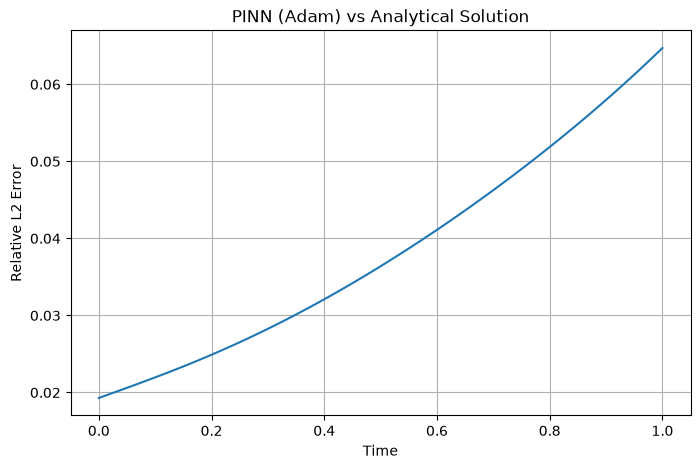

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(t_eval.numpy(), l2_error.numpy())

plt.xlabel("Time")
plt.ylabel("Relative L2 Error")
plt.title("PINN (Adam) vs Analytical Solution")
plt.grid(True)

plt.show()

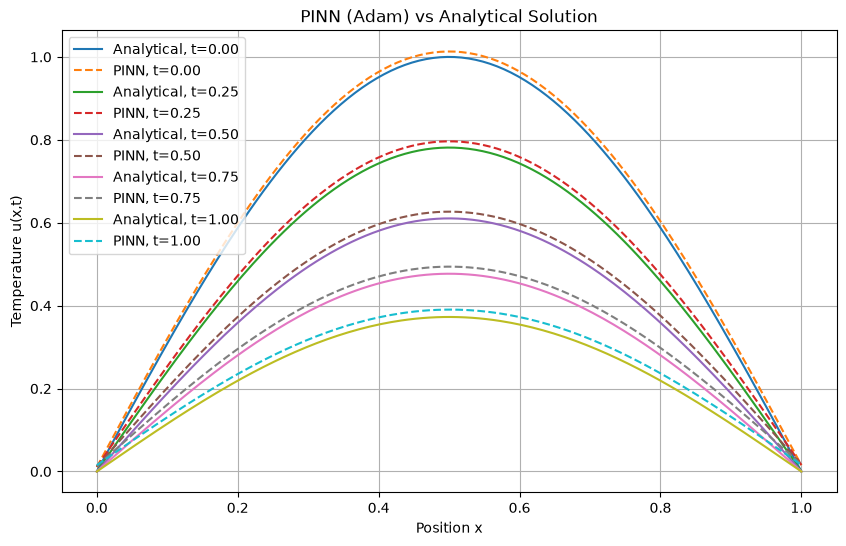

In [ ]:
times = torch.linspace(0, T, 5)

plt.figure(figsize=(10, 6))

for t_value in times:

    # Create inputs for a fixed time
    t_line = torch.full_like(x_eval, t_value.item())
    X_line = torch.stack((x_eval, t_line), dim=1)

    # PINN prediction
    with torch.no_grad():
        u_pinn = model(X_line).squeeze()

    # Analytical solution
    u_analytical = (
        torch.sin(torch.pi * x_eval / L)
        * torch.exp(-alpha * (torch.pi / L)**2 * t_value))

    # Plot both solutions
    plt.plot(
        x_eval.numpy(),
        u_analytical.numpy(),
        label=f"Analytical, t={t_value.item():.2f}")

    plt.plot(
        x_eval.numpy(),
        u_pinn.numpy(),
        "--",
        label=f"PINN, t={t_value.item():.2f}")

plt.xlabel("Position x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN (Adam) vs Analytical Solution")
plt.legend()
plt.grid(True)

plt.show()

# L-BFGS
### We are fine tuning the trained model using Adam optimizer, further using L-BFGS

In [ ]:
import torch
# Optimizer

optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=20,
    history_size=20,
    line_search_fn="strong_wolfe")

iterations = 1000

# Store losses during training

lbfgs_loss_history = []

lbfgs_loss_phys_history = []
lbfgs_loss_IC_history = []
lbfgs_loss_BC_history = [] 


# Function to calculate all losses in the same way as in the Adam version

def calculate_losses():

    # 1. Calculate physics loss
    X_r_grad = X_r.clone().detach().requires_grad_(True)

    u = model(X_r_grad)

    grads = torch.autograd.grad(
        outputs=u,
        inputs=X_r_grad,
        grad_outputs=torch.ones_like(u),
        create_graph=True)[0]

    u_x = grads[:, 0:1]
    u_t = grads[:, 1:2]

    grads_x = torch.autograd.grad(
        outputs=u_x,
        inputs=X_r_grad,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True)[0]

    u_xx = grads_x[:, 0:1]

    residual = u_t - alpha * u_xx

    loss_phys = torch.mean(residual**2)


    # 2. Calculate initial condition loss as in the Adam version
    u_IC = model(X_IC)

    u_IC_exact = torch.sin(torch.pi * X_IC[:, 0:1] / L)

    loss_IC = torch.mean((u_IC - u_IC_exact)**2)


    # 3. Calculate boundary condition loss, also the same as in Adam version
    u_BC_left = model(X_BC_left)
    u_BC_right = model(X_BC_right)

    loss_BC = torch.mean(u_BC_left**2 + u_BC_right**2)


    # 4. Calculate total loss
    loss_total = (
        lambda_phys * loss_phys
        + lambda_IC * loss_IC
        + lambda_BC * loss_BC)

    return loss_total, loss_phys, loss_IC, loss_BC # We return the losses


# Closure function for L-BFGS. LBFGS requires this, to recompute loss and gradients under the optimization

def closure():

    optimizer.zero_grad() # resets the gradients so that it doesnt accumulate

    loss_total, _, _, _ = calculate_losses() # calculating the four losses: total loss, physics loss, IC loss and BC loss, but only saving the first, total_loss

    loss_total.backward() # Calculating gradients and the networks parameters

    return loss_total # Returning the total loss for our LBFGS


# Training loop

for iteration in range(iterations):

    # 5. Update network parameters using L-BFGS
    optimizer.step(closure)

    # 6. Calculate losses after the update
    loss_total, loss_phys, loss_IC, loss_BC = calculate_losses()

    # 7. Store losses for later visualization
    lbfgs_loss_history.append(loss_total.item())

    lbfgs_loss_phys_history.append(loss_phys.item())
    lbfgs_loss_IC_history.append(loss_IC.item())
    lbfgs_loss_BC_history.append(loss_BC.item())

    if (iteration + 1) % 10 == 0:
        print(
            f"Iteration {iteration + 1}/{iterations}, "
            f"Total Loss: {loss_total.item():.8f}, "
            f"Physics: {loss_phys.item():.8f}, "
            f"IC: {loss_IC.item():.8f}, "
            f"BC: {loss_BC.item():.8f}")

Iteration 10/1000, Total Loss: 0.00200169, Physics: 0.00000844, IC: 0.00001007, BC: 0.00002265
Iteration 20/1000, Total Loss: 0.00331203, Physics: 0.00000984, IC: 0.00001903, BC: 0.00004630
Iteration 30/1000, Total Loss: 0.00106627, Physics: 0.00000758, IC: 0.00000248, BC: 0.00000616
Iteration 40/1000, Total Loss: 0.00082196, Physics: 0.00000739, IC: 0.00000108, BC: 0.00000141
Iteration 50/1000, Total Loss: 0.00087233, Physics: 0.00000743, IC: 0.00000157, BC: 0.00000227
Iteration 60/1000, Total Loss: 0.00075442, Physics: 0.00000725, IC: 0.00000040, BC: 0.00000048
Iteration 70/1000, Total Loss: 0.00076856, Physics: 0.00000725, IC: 0.00000041, BC: 0.00000084
Iteration 80/1000, Total Loss: 0.00075174, Physics: 0.00000722, IC: 0.00000041, BC: 0.00000047
Iteration 90/1000, Total Loss: 0.00075061, Physics: 0.00000721, IC: 0.00000042, BC: 0.00000047
Iteration 100/1000, Total Loss: 0.00074883, Physics: 0.00000719, IC: 0.00000037, BC: 0.00000051
Iteration 110/1000, Total Loss: 0.00074668, Physi

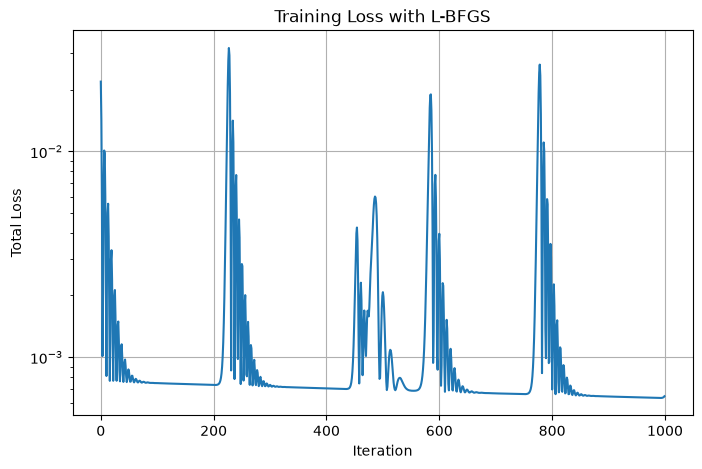

In [21]:
import matplotlib.pyplot as plt

# Plotting the training loss

plt.figure(figsize=(8, 5))

plt.semilogy(lbfgs_loss_history)

plt.xlabel("Iteration")
plt.ylabel("Total Loss")
plt.title("Training Loss with L-BFGS")
plt.grid(True)

plt.show()

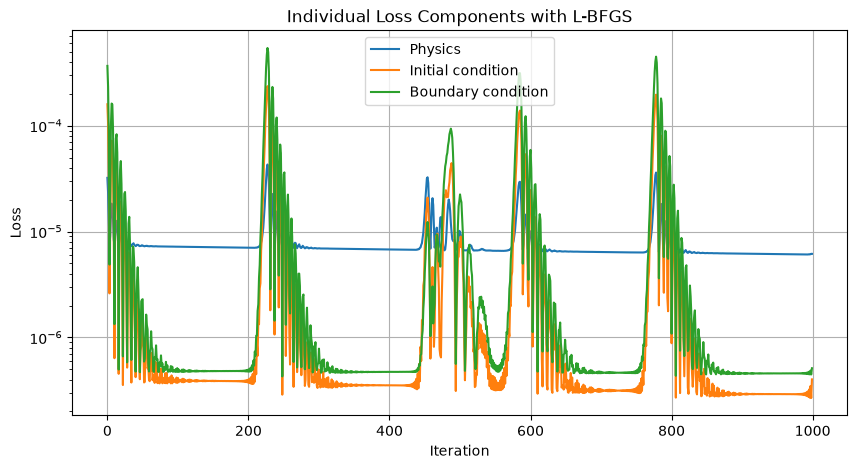

In [22]:
plt.figure(figsize=(10, 5))

plt.semilogy(lbfgs_loss_phys_history, label="Physics")
plt.semilogy(lbfgs_loss_IC_history, label="Initial condition")
plt.semilogy(lbfgs_loss_BC_history, label="Boundary condition")

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Individual Loss Components with L-BFGS")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
# Create evaluation grid
x_eval = torch.linspace(0, L, 200)
t_eval = torch.linspace(0, T, 100)

X_eval, TT_eval = torch.meshgrid(
    x_eval, t_eval, indexing="ij"
)

X_eval_points = torch.stack(
    (X_eval.flatten(), TT_eval.flatten()), dim=1
)

# Predict using the trained PINN
model.eval()

with torch.no_grad():
    u_pred = model(X_eval_points)
    u_pred = u_pred.reshape(200, 100)

    # Analytical solution
    u_exact = (
        torch.sin(torch.pi * X_eval / L)
        * torch.exp(-alpha * (torch.pi / L)**2 * TT_eval)
    )

# Relative L2 error for each time point
l2_error = (
    torch.linalg.norm(u_pred - u_exact, dim=0)
    / torch.linalg.norm(u_exact, dim=0)
)

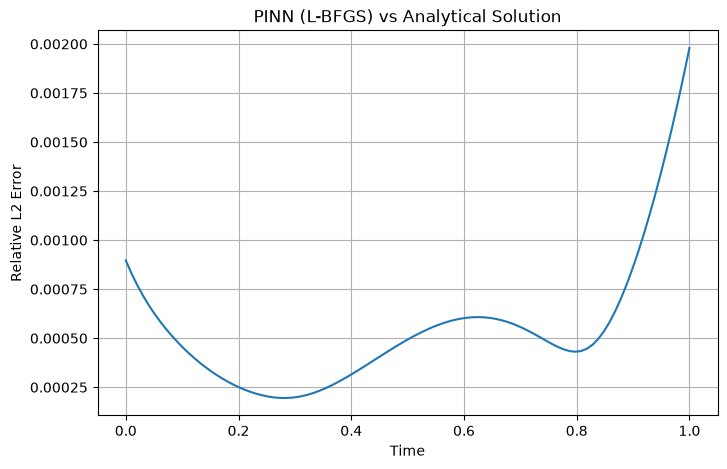

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(t_eval.numpy(), l2_error.numpy())

plt.xlabel("Time")
plt.ylabel("Relative L2 Error")
plt.title("PINN (L-BFGS) vs Analytical Solution")
plt.grid(True)

plt.show()

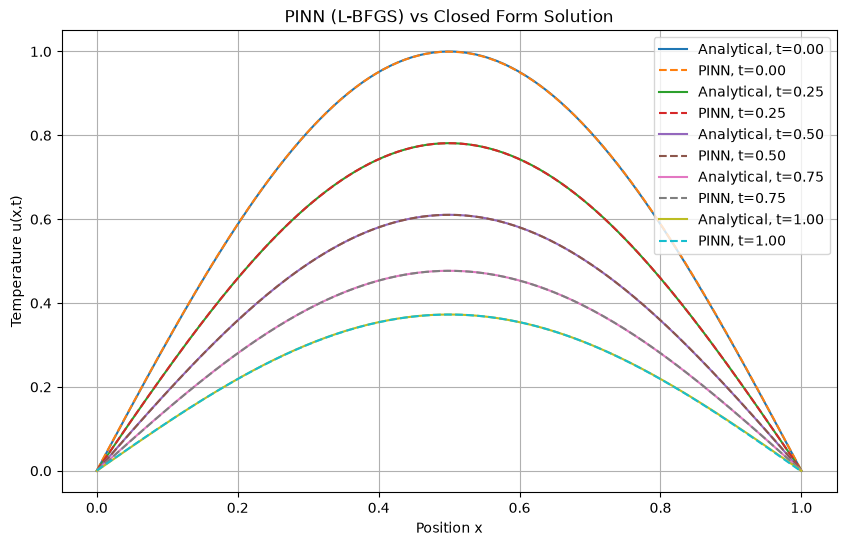

In [26]:
times = torch.linspace(0, T, 5)

plt.figure(figsize=(10, 6))

for t_value in times:

    # Create inputs for a fixed time
    t_line = torch.full_like(x_eval, t_value.item())
    X_line = torch.stack((x_eval, t_line), dim=1)

    # PINN prediction
    with torch.no_grad():
        u_pinn = model(X_line).squeeze()

    # Analytical solution
    u_analytical = (
        torch.sin(torch.pi * x_eval / L)
        * torch.exp(-alpha * (torch.pi / L)**2 * t_value)
    )

    # Plot both solutions
    plt.plot(
        x_eval.numpy(),
        u_analytical.numpy(),
        label=f"Analytical, t={t_value.item():.2f}"
    )

    plt.plot(
        x_eval.numpy(),
        u_pinn.numpy(),
        "--",
        label=f"PINN, t={t_value.item():.2f}"
    )

plt.xlabel("Position x")
plt.ylabel("Temperature u(x,t)")
plt.title("PINN (L-BFGS) vs Closed Form Solution")
plt.legend()
plt.grid(True)

plt.show()